Loaded 11,068 test images
group
Diffusion fake       4516
Real (MS-COCO)       3200
Real (GAN source)    2334
GAN fake             1018 

Mean weight per band:
                   band1  band2  band3  band4  band5  band6  band7  band8
group                                                                    
Real (MS-COCO)     0.301  0.552  0.653  0.721  0.713  0.648  0.541  0.382
Diffusion fake     0.311  0.568  0.667  0.716  0.699  0.625  0.532  0.370
Real (GAN source)  0.328  0.594  0.695  0.701  0.672  0.573  0.517  0.343
GAN fake           0.337  0.608  0.707  0.695  0.658  0.548  0.508  0.331 

SD across images per band:
                   band1  band2  band3  band4  band5  band6  band7  band8
group                                                                    
Real (MS-COCO)     0.011  0.016  0.015  0.004  0.012  0.021  0.007  0.011
Diffusion fake     0.014  0.022  0.019  0.007  0.020  0.035  0.014  0.017
Real (GAN source)  0.028  0.044  0.043  0.020  0.043  0.077  0.025  0.0

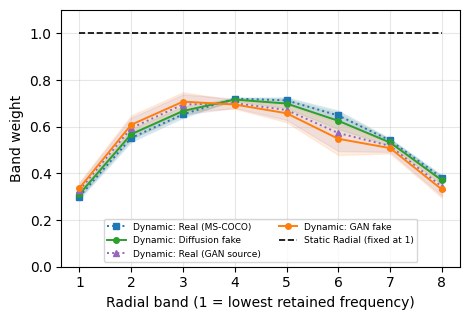


Saved: /kaggle/working/fig4_band_weights.png  and  /kaggle/working/band_weight_summary.csv


In [1]:
# =============================================================================
# Fig. 4 — Learned band weights of Dynamic FreqNet vs Static Radial control
# Needs: band_weights_test_dynamic_c0.20_seed42.csv (from the final training session)
# Optional: static_ring checkpoint (learned shared weights)
# =============================================================================
import glob, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ---- Set these only if auto-search picks the wrong file (else leave None) ----
DYNAMIC_CSV_OVERRIDE = "/kaggle/input/datasets/mikekomari/bandweights/band_weights_test_dynamic_c0.20_seed42.csv"        # e.g. "/kaggle/input/my-notebook/band_weights_test_dynamic_c0.20_seed42.csv"
STATIC_RING_CKPT_OVERRIDE = None   # e.g. "/kaggle/input/my-static/best_freqnet_static_ring_c0.20_seed42.pt"

K = 8
OUT_DIR = Path("/kaggle/working")


def find_newest(pattern):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True) + \
           glob.glob(f"/kaggle/working/**/{pattern}", recursive=True)
    if not hits:
        return None
    if len(hits) > 1:
        print(f"Found {len(hits)} files for '{pattern}':")
        for h in hits:
            print("   ", h)
    newest = max(hits, key=os.path.getmtime)
    print(f"Using: {newest}\n")
    return Path(newest)


# ---------------------------------------------------------------- 1. Load data
csv_path = Path(DYNAMIC_CSV_OVERRIDE) if DYNAMIC_CSV_OVERRIDE else find_newest("band_weights_test_dynamic_c0.20_seed42.csv")
if csv_path is None or not csv_path.exists():
    raise FileNotFoundError("Dynamic band-weight CSV not found. Attach the final training session's output, "
                            "or set DYNAMIC_CSV_OVERRIDE.")

df = pd.read_csv(csv_path)
w_cols = [f"w{k}" for k in range(K)]
print(f"Loaded {len(df):,} test images")

fname = df["path"].astype(str).str.split("/").str[-1]
df["group"] = np.select(
    [(df["label"] == 0) & fname.str.startswith("gan_"),
     (df["label"] == 0),
     fname.str.startswith("gan_")],
    ["Real (GAN source)", "Real (MS-COCO)", "GAN fake"],
    default="Diffusion fake",
)
print(df["group"].value_counts().to_string(), "\n")

# ---------------------------------------------------------------- 2. Summary numbers
GROUPS = ["Real (MS-COCO)", "Diffusion fake", "Real (GAN source)", "GAN fake"]
means = df.groupby("group")[w_cols].mean().reindex(GROUPS)
stds = df.groupby("group")[w_cols].std().reindex(GROUPS)
means.columns = stds.columns = [f"band{k + 1}" for k in range(K)]

print("Mean weight per band:")
print(means.round(3).to_string(), "\n")
print("SD across images per band:")
print(stds.round(3).to_string(), "\n")

def max_gap(a, b):
    d = (means.loc[a] - means.loc[b]).abs()
    return d.max(), d.idxmax()

for a, b in [("Real (MS-COCO)", "Diffusion fake"),
             ("Real (GAN source)", "GAN fake"),
             ("GAN fake", "Diffusion fake"),
             ("Real (GAN source)", "Real (MS-COCO)")]:
    gap, band = max_gap(a, b)
    print(f"Max |{a} - {b}| = {gap:.3f} at {band}")

summary = pd.concat({"mean": means, "sd": stds}, axis=1)
summary.to_csv(OUT_DIR / "band_weight_summary.csv")

# ---------------------------------------------------------------- 3. Optional static_ring
shared = None
ring_ckpt = Path(STATIC_RING_CKPT_OVERRIDE) if STATIC_RING_CKPT_OVERRIDE else find_newest("best_freqnet_static_ring_*.pt")
if ring_ckpt is not None and ring_ckpt.exists():
    ckpt = torch.load(ring_ckpt, map_location="cpu", weights_only=False)
    state = ckpt.get("model_state_dict", ckpt)
    state = {k.replace("module.", ""): v for k, v in state.items()}
    if "backbone.static_band_logits" in state:
        shared = torch.sigmoid(state["backbone.static_band_logits"]).numpy()
        print("\nStatic learned (shared) weights:", np.round(shared, 3).tolist())
else:
    print("\nNo static_ring checkpoint found — skipping that line.")

# ---------------------------------------------------------------- 4. Plot
bands = np.arange(1, K + 1)
style = {
    "Real (MS-COCO)":    dict(color="tab:blue",   marker="s", linestyle=":"),
    "Diffusion fake":    dict(color="tab:green",  marker="o", linestyle="-"),
    "Real (GAN source)": dict(color="tab:purple", marker="^", linestyle=":"),
    "GAN fake":          dict(color="tab:orange", marker="o", linestyle="-"),
}

fig, ax = plt.subplots(figsize=(4.8, 3.3))
for g in GROUPS:
    if g not in means.index or means.loc[g].isna().all():
        continue
    m, s = means.loc[g].values, stds.loc[g].values
    ax.plot(bands, m, label=f"Dynamic: {g}", markersize=4, linewidth=1.4, **style[g])
    ax.fill_between(bands, m - s, m + s, color=style[g]["color"], alpha=0.12)

ax.plot(bands, np.ones(K), "k--", linewidth=1.2, label="Static Radial (fixed at 1)")
if shared is not None:
    ax.plot(bands, shared, color="gray", marker="D", markersize=4, linewidth=1.2,
            label="Static learned (shared)")

ax.set_xlabel("Radial band (1 = lowest retained frequency)")
ax.set_ylabel("Band weight")
ax.set_xticks(bands)
ax.set_ylim(0, 1.1)
ax.grid(alpha=0.3)
ax.legend(fontsize=6.5, loc="lower center", ncol=2, frameon=True)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig4_band_weights.png", dpi=300)
plt.show()

print(f"\nSaved: {OUT_DIR / 'fig4_band_weights.png'}  and  {OUT_DIR / 'band_weight_summary.csv'}")